# Классификация видов спорта с ResNet18

Многоклассовая классификация изображений: собственная реализация ResNet18 обучается с нуля распознавать 30 видов спорта. Эксперимент использует отдельные train, validation и test-выборки, а лучшая модель выбирается только по validation accuracy.

## 1. Окружение и воспроизводимость

Код автоматически использует CUDA при наличии. Фиксированный seed делает разбиение и обучение более воспроизводимыми.

In [1]:
import json
import os
import random
import zipfile
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CyclicLR
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2
from tqdm.auto import tqdm

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

C:\DS_dive\pet_projects\sports-classification-resnet18\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


## 2. Загрузка данных

Архив скачивается только при отсутствии `data/sports.csv`. Фотографии не загружаются в память заранее: датасет открывает нужный файл в `__getitem__`.
В архиве нет физической папки `valid`, поэтому validation-выборка создаётся из `train` со стратификацией по классам.


In [2]:
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
DATA_DIR.mkdir(exist_ok=True)
ARTIFACTS_DIR.mkdir(exist_ok=True)

archive_path = DATA_DIR / "sports.zip"
csv_path = DATA_DIR / "sports.csv"

if not csv_path.exists():
    if not archive_path.exists():
        gdown.download(
            id="1biITy7cv0-lo-bwZrFkyDCGsEOWCBx5W",
            output=str(archive_path),
            quiet=False,
        )
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(DATA_DIR)

if not csv_path.exists():
    raise FileNotFoundError(f"sports.csv not found in {DATA_DIR}")

df = pd.read_csv(csv_path)
print("rows:", len(df), "classes:", df["labels"].nunique())
print(df["data set"].value_counts())
df.head()

rows: 14493 classes: 100
data set
train    13493
test       500
valid      500
Name: count, dtype: int64


,class id,filepaths,labels,data set
0,0,train/air hockey/001.jpg,air hockey,train
1,0,train/air hockey/002.jpg,air hockey,train
2,0,train/air hockey/003.jpg,air hockey,train
3,0,train/air hockey/004.jpg,air hockey,train
4,0,train/air hockey/005.jpg,air hockey,train


In [3]:
N_CLASSES = 30
subset = df[df["class id"] < N_CLASSES].copy()
source_train_df = subset[subset["data set"] == "train"].reset_index(drop=True)
test_df = subset[subset["data set"] == "test"].reset_index(drop=True)

# В скачанном архиве нет папки valid, хотя такие пути указаны в sports.csv.
# Поэтому validation отделяем от реальной train-папки со стратификацией по классам.
train_df, val_df = train_test_split(
    source_train_df,
    test_size=0.15,
    random_state=SEED,
    stratify=source_train_df["class id"],
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

class_names = (
    subset[["class id", "labels"]]
    .drop_duplicates()
    .sort_values("class id")["labels"]
    .tolist()
)

for split_name, frame in {"train": train_df, "validation": val_df, "test": test_df}.items():
    missing = [path for path in frame["filepaths"] if not (DATA_DIR / path).is_file()]
    if missing:
        raise FileNotFoundError(
            f"{split_name}: не найдено {len(missing)} файлов; первый путь: {missing[0]}"
        )

print("train/validation/test:", len(train_df), len(val_df), len(test_df))
print("classes:", class_names)


train/validation/test: 3401 601 150
classes: ['air hockey', 'ampute football', 'archery', 'arm wrestling', 'axe throwing', 'balance beam', 'barell racing', 'baseball', 'basketball', 'baton twirling', 'bike polo', 'billiards', 'bmx', 'bobsled', 'bowling', 'boxing', 'bull riding', 'bungee jumping', 'canoe slamon', 'cheerleading', 'chuckwagon racing', 'cricket', 'croquet', 'curling', 'disc golf', 'fencing', 'field hockey', 'figure skating men', 'figure skating pairs', 'figure skating women']


## 3. Аугментации и DataLoader

Вертикальный переворот и перестановка каналов могут быть спорными для части спортивных сцен, поэтому применяются с небольшой вероятностью. Их влияние стоит проверить отдельным ablation-экспериментом.

In [4]:
class SportDataset(Dataset):
    def __init__(self, frame, root, train=False):
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root)
        self.train = train
        self.to_tensor = v2.Compose([
            v2.ToImage(),
            v2.ToDtype(torch.float32, scale=True),
        ])
        self.augment = v2.Compose([
            v2.RandomHorizontalFlip(p=0.5),
            v2.RandomVerticalFlip(p=0.1),
            v2.RandomApply([v2.ElasticTransform(alpha=8.0, sigma=4.0)], p=0.25),
            v2.RandomApply([v2.RandomChannelPermutation()], p=0.1),
        ])
        self.normalize = v2.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        )

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(self.root / row["filepaths"]) as image_file:
            image = self.to_tensor(image_file.convert("RGB"))
        if self.train:
            image = self.augment(image)
        image = self.normalize(image)
        return image, int(row["class id"])

dataset_train = SportDataset(train_df, DATA_DIR, train=True)
dataset_val = SportDataset(val_df, DATA_DIR)
dataset_test = SportDataset(test_df, DATA_DIR)

loader_kwargs = {
    "num_workers": 0,
    "pin_memory": torch.cuda.is_available(),
}
dataloader_train = DataLoader(dataset_train, batch_size=32, shuffle=True, **loader_kwargs)
dataloader_val = DataLoader(dataset_val, batch_size=64, shuffle=False, **loader_kwargs)
dataloader_test = DataLoader(dataset_test, batch_size=64, shuffle=False, **loader_kwargs)

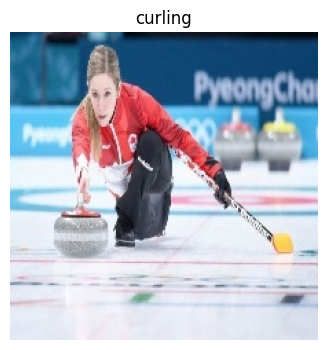

In [5]:
sample_image, sample_label = dataset_train[0]
mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
preview = (sample_image * std + mean).permute(1, 2, 0).clamp(0, 1)
plt.figure(figsize=(4, 4))
plt.imshow(preview)
plt.title(class_names[sample_label])
plt.axis("off")
plt.show()

## 4. ResNet18 с нуля

Архитектура состоит из четырёх стадий по два residual-блока. При смене числа каналов или пространственного размера shortcut преобразуется свёрткой 1×1.

In [6]:
from torch import nn  # Импортируем базовые слои PyTorch.

class ResidualBlock(nn.Module):  # Создаем базовый остаточный блок ResNet.
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):  # Задаем слои блока и, при необходимости, shortcut.
        super().__init__()  # Инициализируем родительский класс nn.Module.
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)  # Выполняем первую свертку блока без bias.
        self.bn1 = nn.BatchNorm2d(out_channels)  # Нормализуем выход первой свертки.
        self.relu = nn.ReLU(inplace=True)  # Добавляем нелинейность после сверток.
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)  # Выполняем вторую свертку без изменения размера.
        self.bn2 = nn.BatchNorm2d(out_channels)  # Нормализуем выход второй свертки.
        self.downsample = downsample  # Сохраняем преобразование shortcut при смене размерности.

    def forward(self, x):  # Пропускаем вход через сверточный блок и остаточную связь.
        identity = x  # Сохраняем исходный тензор для сложения с результатом блока.
        out = self.conv1(x)  # Применяем первую свертку.
        out = self.bn1(out)  # Нормализуем результат первой свертки.
        out = self.relu(out)  # Применяем ReLU перед второй сверткой.
        out = self.conv2(out)  # Применяем вторую свертку.
        out = self.bn2(out)  # Нормализуем результат второй свертки.
        if self.downsample is not None:  # Меняем размер shortcut, если меняется размер или число каналов.
            identity = self.downsample(x)  # Приводим shortcut к размеру результата блока.
        out = out + identity  # Складываем выход блока с остаточной связью.
        out = self.relu(out)  # Применяем ReLU после сложения.
        return out  # Возвращаем результат остаточного блока.

class ResNet18(nn.Module):  # Реализуем ResNet18 для заданного числа классов.
    def __init__(self, num_classes=30):  # Создаем начальные слои, четыре стадии и классификатор.
        super().__init__()  # Инициализируем родительский класс nn.Module.
        self.in_channels = 64  # Запоминаем число каналов, поступающих в первую стадию.
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)  # Обрабатываем RGB-вход начальной сверткой без bias.
        self.bn1 = nn.BatchNorm2d(64)  # Нормализуем начальные признаки.
        self.relu = nn.ReLU(inplace=True)  # Задаем функцию активации сети.
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)  # Уменьшаем пространственный размер признаков.
        self.layer1 = self._make_layer(64, blocks=2, stride=1)  # Создаем первую стадию из двух блоков.
        self.layer2 = self._make_layer(128, blocks=2, stride=2)  # Создаем вторую стадию с уменьшением разрешения.
        self.layer3 = self._make_layer(256, blocks=2, stride=2)  # Создаем третью стадию с уменьшением разрешения.
        self.layer4 = self._make_layer(512, blocks=2, stride=2)  # Создаем четвертую стадию с уменьшением разрешения.
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))  # Усредняем каждый канал до одного значения.
        self.fc = nn.Linear(512, num_classes)  # Преобразуем признаки в оценки заданных классов.

    def _make_layer(self, out_channels, blocks, stride):  # Строим стадию из остаточных блоков.
        downsample = None  # По умолчанию shortcut оставляет вход без изменений.
        if stride != 1 or self.in_channels != out_channels:  # Проверяем, изменятся ли размер или каналы.
            downsample = nn.Sequential(nn.Conv2d(self.in_channels, out_channels, kernel_size=1, stride=stride, bias=False), nn.BatchNorm2d(out_channels))  # Согласуем размерность shortcut сверткой 1x1 без bias.
        layers = [ResidualBlock(self.in_channels, out_channels, stride, downsample)]  # Добавляем первый блок стадии.
        self.in_channels = out_channels  # Обновляем число каналов для следующих блоков.
        for _ in range(1, blocks):  # Добавляем оставшиеся блоки с неизменной размерностью.
            layers.append(ResidualBlock(self.in_channels, out_channels))  # Добавляем очередной остаточный блок.
        return nn.Sequential(*layers)  # Объединяем блоки стадии в один модуль.

    def forward(self, x):  # Определяем полный прямой проход ResNet18.
        out = self.conv1(x)  # Извлекаем начальные признаки сверткой.
        out = self.bn1(out)  # Нормализуем начальные признаки.
        out = self.relu(out)  # Применяем ReLU.
        out = self.maxpool(out)  # Уменьшаем размер карт признаков.
        out = self.layer1(out)  # Передаем признаки через первую стадию.
        out = self.layer2(out)  # Передаем признаки через вторую стадию.
        out = self.layer3(out)  # Передаем признаки через третью стадию.
        out = self.layer4(out)  # Передаем признаки через четвертую стадию.
        out = self.avgpool(out)  # Усредняем признаки по пространственным координатам.
        out = torch.flatten(out, 1)  # Превращаем карты признаков в вектор для классификатора.
        out = self.fc(out)  # Получаем оценки каждого класса.
        return out  # Возвращаем логиты без softmax для CrossEntropyLoss.

In [7]:
model = ResNet18(num_classes=N_CLASSES).to(device)
with torch.no_grad():
    output_shape = model(torch.randn(2, 3, 224, 224, device=device)).shape
print("output shape:", output_shape)
assert output_shape == (2, N_CLASSES)

output shape: torch.Size([2, 30])


## 5. Обучение и выбор лучшей модели

Test-выборка не участвует в настройке. После каждой эпохи считается validation accuracy, и лучший чекпоинт сохраняется в `artifacts/`.

In [8]:
def evaluate(model, dataloader):
    model.eval()
    total_loss = 0.0
    predictions = []
    targets = []
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(images)
            total_loss += F.cross_entropy(logits, labels).item() * labels.size(0)
            predictions.append(logits.argmax(dim=1).cpu())
            targets.append(labels.cpu())
    predictions = torch.cat(predictions)
    targets = torch.cat(targets)
    accuracy = (predictions == targets).float().mean().item()
    return total_loss / len(dataloader.dataset), accuracy, predictions, targets

def save_checkpoint(path, epoch, model, optimizer, val_accuracy):
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_accuracy": val_accuracy,
        "class_names": class_names,
    }, path)

In [9]:
N_EPOCHS = 20
checkpoint_path = ARTIFACTS_DIR / "resnet18_best.pth"
model = ResNet18(num_classes=N_CLASSES).to(device)
optimizer = AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = CyclicLR(
    optimizer,
    base_lr=1e-4,
    max_lr=1e-3,
    step_size_up=max(1, len(dataloader_train) * 3),
    mode="triangular",
    cycle_momentum=False,
)

history = {"train_loss": [], "val_loss": [], "val_accuracy": []}
best_val_accuracy = -1.0

for epoch in range(1, N_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for images, labels in tqdm(dataloader_train, desc=f"epoch {epoch}/{N_EPOCHS}", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = F.cross_entropy(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()
        running_loss += loss.item() * labels.size(0)

    train_loss = running_loss / len(dataset_train)
    val_loss, val_accuracy, _, _ = evaluate(model, dataloader_val)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        save_checkpoint(checkpoint_path, epoch, model, optimizer, val_accuracy)

    print(
        f"epoch {epoch:02d} | train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | val_accuracy={val_accuracy:.4f}"
    )

epoch 01 | train_loss=2.6805 | val_loss=3.2561 | val_accuracy=0.1997


epoch 02 | train_loss=2.3509 | val_loss=2.3754 | val_accuracy=0.3261


epoch 03 | train_loss=2.1331 | val_loss=2.3756 | val_accuracy=0.3111


epoch 04 | train_loss=1.9663 | val_loss=1.7165 | val_accuracy=0.4626


epoch 05 | train_loss=1.6768 | val_loss=1.5188 | val_accuracy=0.5724


epoch 06 | train_loss=1.3620 | val_loss=1.2315 | val_accuracy=0.6156


... (10 outputs left out)

epoch 17 | train_loss=0.7066 | val_loss=1.0030 | val_accuracy=0.7005


epoch 18 | train_loss=0.5198 | val_loss=0.8183 | val_accuracy=0.7371


epoch 19 | train_loss=0.4212 | val_loss=0.9591 | val_accuracy=0.6988


epoch 20 | train_loss=0.5507 | val_loss=1.5775 | val_accuracy=0.5857


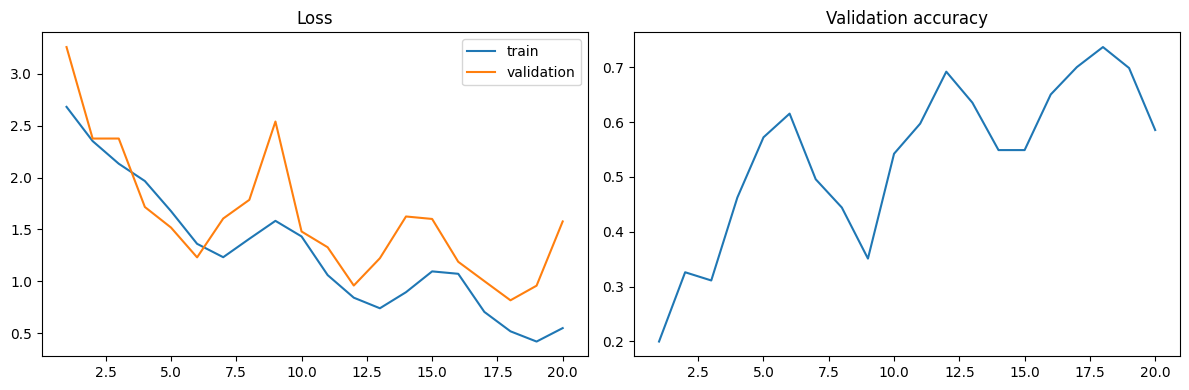

In [10]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(epochs, history["val_accuracy"])
axes[1].set_title("Validation accuracy")
plt.tight_layout()
plt.show()

## 6. Финальная оценка на test

Эта ячейка запускается после завершения обучения. Она загружает лучший по validation чекпоинт и один раз оценивает его на test.

best epoch: 18
validation accuracy: 0.7371
test loss: 0.4520
test accuracy: 0.8800
                      precision    recall  f1-score   support

          air hockey     0.8333    1.0000    0.9091         5
     ampute football     1.0000    0.8000    0.8889         5
             archery     0.8000    0.8000    0.8000         5
       arm wrestling     1.0000    1.0000    1.0000         5
        axe throwing     1.0000    0.8000    0.8889         5
        balance beam     1.0000    1.0000    1.0000         5
       barell racing     1.0000    0.8000    0.8889         5
            baseball     0.8333    1.0000    0.9091         5
          basketball     0.8000    0.8000    0.8000         5
      baton twirling     0.8333    1.0000    0.9091         5
           bike polo     0.8333    1.0000    0.9091         5
           billiards     1.0000    1.0000    1.0000         5
                 bmx     1.0000    0.4000    0.5714         5
             bobsled     0.8333    1.0000    0.9

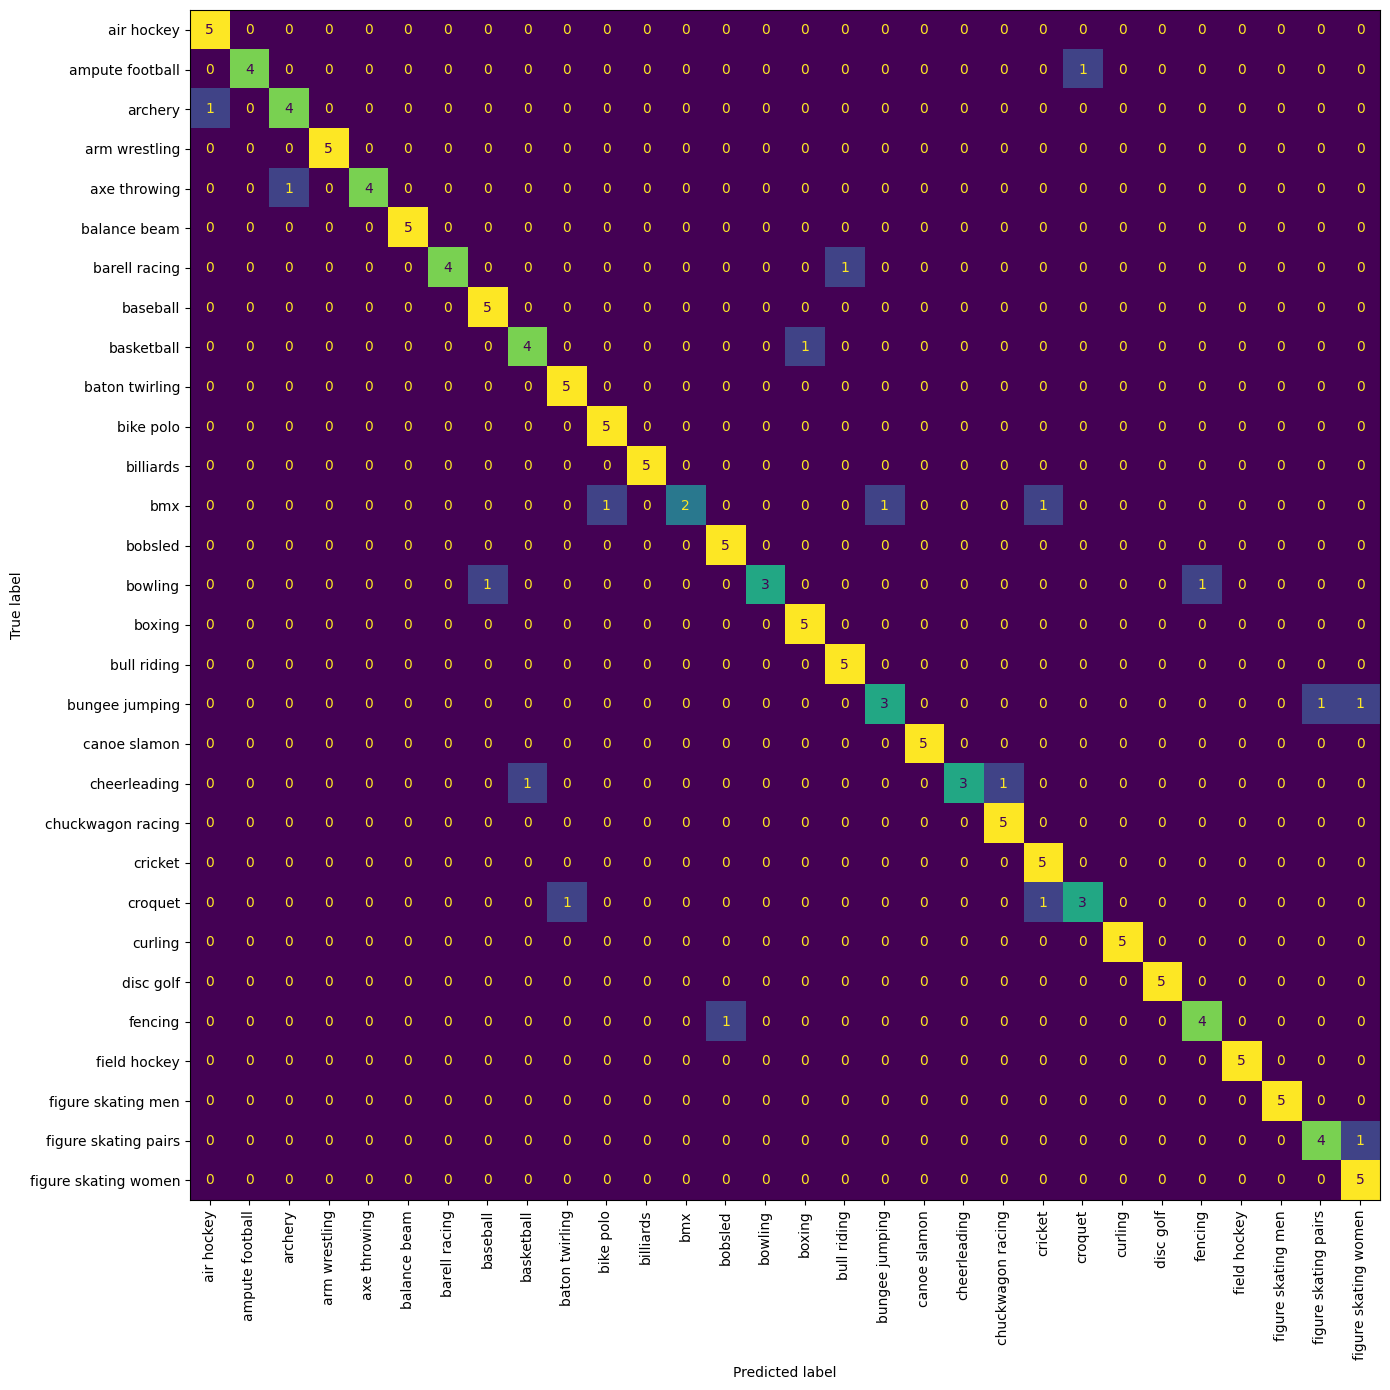

141

In [11]:
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
test_loss, test_accuracy, y_pred, y_true = evaluate(model, dataloader_test)

print(f"best epoch: {checkpoint['epoch']}")
print(f"validation accuracy: {checkpoint['val_accuracy']:.4f}")
print(f"test loss: {test_loss:.4f}")
print(f"test accuracy: {test_accuracy:.4f}")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    xticks_rotation=90,
    colorbar=False,
    ax=ax,
)
plt.tight_layout()
plt.show()

metrics = {
    "best_epoch": checkpoint["epoch"],
    "validation_accuracy": checkpoint["val_accuracy"],
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
}
(ARTIFACTS_DIR / "metrics.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8"
)

## Что анализировать после запуска

- разницу между validation и test accuracy;
- классы с низкими precision/recall;
- пары классов, которые модель чаще всего путает;
- влияние вертикального переворота и перестановки каналов в отдельном ablation-эксперименте;
- признаки переобучения на графиках loss.